# MCMC와 정보량

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## Monte Carlo: 버스를 놓칠 확률

06:00을 0분으로 둔다. 기상 시각 A~N(0,3²), 준비시간 B~N(20,3²), 도보시간 C~N(10,3²), 버스 도착 D~N(35,5²)를 서로 독립으로 가정한다. 여유시간 D−(A+B+C)이 음수일 확률을 구하시오.

음의 여유시간은 버스를 놓친 경우. 다음 버스까지의 대기시간은 이 모형에 포함하지 않음

In [2]:
from scipy.stats import norm
rng=np.random.default_rng(42)
A=rng.normal(0,3,100_000);B=rng.normal(20,3,100_000)
C=rng.normal(10,3,100_000);D=rng.normal(35,5,100_000)
slack=D-(A+B+C)
theory=norm.cdf(0,loc=5,scale=np.sqrt(52))
print('모의실험:',np.mean(slack<0),'정규분포 계산:',theory)
print('10분 일찍 일어날 때:',np.mean(slack+10<0))
assert abs(np.mean(slack<0)-theory)<.01

모의실험: 0.24481 정규분포 계산: 0.24403704658262404
10분 일찍 일어날 때: 0.01922


## 비와 확률분포

전이행렬 `[[0.8,0.2],[0.4,0.6]]`의 행은 현재 맑음·비, 열은 다음 맑음·비이다. 처음 맑은 상태에서 확률을 반복 갱신하고 장기 비율을 구하시오.

In [3]:
P = np.array([[.8,.2],[.4,.6]])
p = np.array([1.,0.])
for _ in range(50): p = p @ P
print(p)
assert np.allclose(p, [2/3,1/3])
# 비대칭 제안: 7→8은 .8, 8→7은 .2, 목표 확률은 같음
print('실제 이동 확률:', .8*min(1,.2/.8), .2*min(1,.8/.2))

[0.66667 0.33333]
실제 이동 확률: 0.2 0.2


## Metropolis 표본추출

목표 함수는 두 봉우리의 합. 정규화 상수 없이 f(제안)/f(현재) 계산. 대칭 제안이므로 제안밀도는 약분. 거절 시 현재 상태를 한 번 더 기록.

시작값 7, 제안 표준편차 4, 5,000회, 초기 500회 제외 조건으로 평균을 구하시오.

수락률: 0.467 평균: 7.108311150360376 이론 평균: 7.0
표본 분산: 23.034592241423603 이론 분산: 23.5


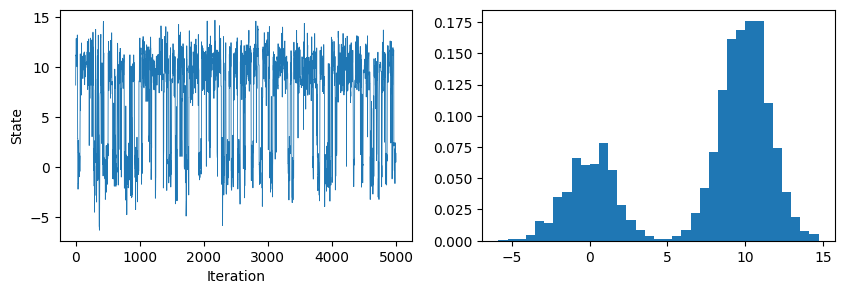

In [4]:
def log_f(x):
    return np.logaddexp(np.log(.3)-.2*x*x, np.log(.7)-.2*(x-10)**2)
def metropolis(step_sd=4., n=5000, seed=42):
    rng = np.random.default_rng(seed)
    chain = np.empty(n); current = 7.; accepted = 0
    for i in range(n):
        proposal = current + rng.normal(0,step_sd)
        if np.log(rng.random()) < min(0., log_f(proposal)-log_f(current)):
            current = proposal; accepted += 1
        chain[i] = current
    return chain, accepted/n
chain, rate = metropolis()
retained = chain[500:]
print('수락률:', rate, '평균:', retained.mean(), '이론 평균:', 7.)
print('표본 분산:', retained.var(), '이론 분산:', 23.5)
fig, ax = plt.subplots(1,2,figsize=(10,3))
ax[0].plot(chain,lw=.6); ax[0].set(xlabel='Iteration',ylabel='State')
ax[1].hist(retained,bins=35,density=True); plt.show()

제안 표준편차를 0.2와 12로 바꾸시오. 수락률·봉우리 간 이동·평균을 함께 비교하시오. 수락률이 높다는 이유만으로 좋은 표본추출이라고 말할 수 있는지 설명하시오.

## 엔트로피와 교차엔트로피

확률 p=[0.3,0.7], 예측 q=[0.5,0.5]의 엔트로피·교차엔트로피·KL 발산을 계산하시오. 로그 밑은 2로 두시오.

In [5]:
p = np.array([.3,.7]); q = np.array([.5,.5])
H = -np.sum(p*np.log2(p))
CE = -np.sum(p*np.log2(q))
KL = np.sum(p*np.log2(p/q))
print('H, CE, KL:', H, CE, KL)
assert np.isclose(CE-H,KL)

H, CE, KL: 0.8812908992306927 1.0 0.1187091007693073
